# Complex analysis 8: Conformal maps and the flow around a wing

*Learning path: complex analysis, part 8 of 8.* [Index](README.md) · Previous: [Real integrals](07-real-integrals.ipynb)

In 1910 Nikolai Joukowski computed the lift of an aircraft wing, a hard problem in fluid dynamics, by solving an easy
one: air flowing around a round cylinder. He then mapped the circle onto a wing shape with the function $z + 1/z$.
The trick works because analytic functions preserve angles, and they turn solutions of Laplace's equation into other
solutions of Laplace's equation. This last lesson of the path shows why, builds the maps that do the work (Möbius
maps and the Joukowski map), and draws the flow of an ideal fluid past a cylinder and past a wing.

**Who this is for.** You have done the [path](README.md) through [lesson 2](02-analytic-functions.ipynb) (harmonic
functions) and [lesson 1](01-complex-functions.ipynb) (`cmap`). Lessons 3 to 7 are not needed here.

**What you will be able to do afterwards:**

1. explain why an analytic map with $f'(a) \ne 0$ preserves angles at $a$, and compute its local rotation and scale;
2. use Möbius maps, and map the upper half plane onto the unit disc;
3. write the complex potential of a flow and draw its streamlines;
4. build a Joukowski airfoil and describe how the cylinder flow carries over to it.

Plan about an hour.

## 1. Analytic maps preserve angles

Near a point $a$, $f(a + h) \approx f(a) + f'(a)h$. Multiplying by the complex number $f'(a) = |f'(a)|e^{i\alpha}$
rotates by $\alpha$ and scales by $|f'(a)|$, the same for every direction $h$. So two curves crossing at $a$ at some angle
have images crossing at the same angle: the map is **conformal** wherever $f' \ne 0$. For $z^2$ at $1 + i$:

In [1]:
subs(diff(z^2, z), z, 1 + i)
simplify(abs(2 + 2*i))
arg(2 + 2*i)

2+2*i

> `subs`: Replaces the variable x by a value.

2*sqrt(2)

> `simplify`: simplify(expr) writes expr in one fixed form: a fraction N/D of multiplied-out polynomials (in the symbols, constants and functions of expr) with common factors cancelled, square roots moved out of denominators, and sin^2 + cos^2 = 1 used in whichever direction is shorter.

pi/4

> `arg` (see `real`): Real part, imaginary part, complex conjugate, modulus |z| and argument (angle) of z.

Near $1 + i$, squaring rotates by $\pi/4$ and stretches by $2\sqrt2$. At $z = 0$, where $(z^2)' = 0$, conformality fails:
angles at 0 are doubled. Here is what $z^2$ does to a small grid around $1 + i$. The images still cross at right
angles, as lesson 1 noticed:

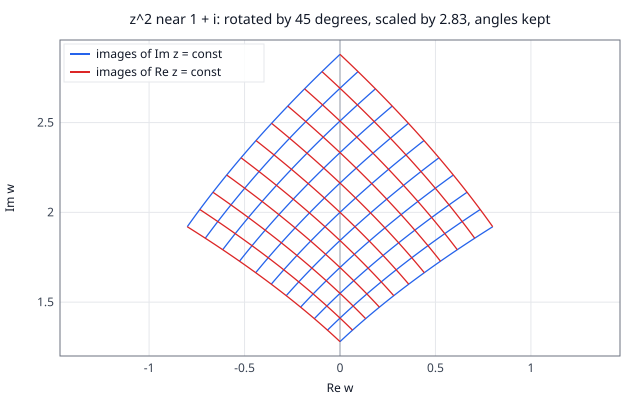

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [2]:
p = cmap(z^2, z, 0.8, 1.2, 0.8, 1.2);
labels(title(p, "z^2 near 1 + i: rotated by 45 degrees, scaled by 2.83, angles kept"), "Re w", "Im w")

**Try this.** Where is $e^z$ conformal? Where is $z^3 - 3z$ not conformal?

## 2. Möbius maps

The maps $w = \dfrac{az + b}{cz + d}$ with $ad - bc \ne 0$ are the **Möbius** (or linear fractional) maps. They are
compositions of translations, rotations, scalings and the inversion $1/z$, and they send circles and lines to circles
and lines. The most useful one is the **Cayley map** $w = (z - i)/(z + i)$, which sends the upper half plane onto the
unit disc: a point $z$ with $\operatorname{Im} z > 0$ is closer to $i$ than to $-i$, so $|w| < 1$.

sqrt(10)/5

> `simplify`: simplify(expr) writes expr in one fixed form: a fraction N/D of multiplied-out polynomials (in the symbols, constants and functions of expr) with common factors cancelled, square roots moved out of denominators, and sin^2 + cos^2 = 1 used in whichever direction is shorter.

0

> `subs`: Replaces the variable x by a value.

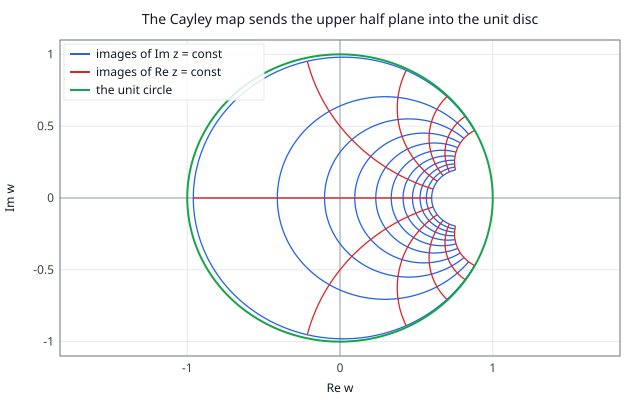

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [3]:
simplify(abs(subs((z - i)/(z + i), z, 2 + 3*i)))
subs((z - i)/(z + i), z, i)
p = cmap((z - i)/(z + i), z, -4, 4, 0.02, 4);
p = show(p, parametric(cos(t), sin(t), t, 0, 2*pi));
p = legend(p, "images of Im z = const", "images of Re z = const", "the unit circle");
labels(title(p, "The Cayley map sends the upper half plane into the unit disc"), "Re w", "Im w")

Horizontal lines become circles touching the unit circle at $w = 1$ (the image of $\infty$); vertical lines become
circular arcs through 1, crossing them at right angles. A problem posed in the half plane can be moved to the disc and
back. That matters because, as the next section shows, conformal maps carry solutions of Laplace's equation along.

**Try this.** Where does the Cayley map send the real axis? The point $z = 0$? Check $|w|$ for $z = 5$.

## 3. Ideal flow and the complex potential

For a steady, incompressible, irrotational flow in the plane the velocity is $\mathbf v = \nabla\phi$ with
$\nabla^2\phi = 0$. By lesson 2, $\phi$ is the real part of an analytic **complex potential** $F = \phi + i\psi$, and the
level curves of $\psi$ are perpendicular to those of $\phi$: they are the **streamlines**, the paths the fluid follows.
The velocity is $\overline{F'(z)}$.

* $F = Uz$: uniform flow to the right with speed $U$.
* $F = U(z + 1/z)$: uniform flow around a cylinder of radius 1. On $|z| = 1$, $z + 1/z = 2\cos\theta$ is real, so
  $\psi = 0$ there: the circle is a streamline, and no fluid crosses it.

In [4]:
imag((x + i*y) + 1/(x + i*y))

y-y/(x^2+y^2)

> `imag` (see `real`): Real part, imaginary part, complex conjugate, modulus |z| and argument (angle) of z.

So $\psi = y - y/(x^2 + y^2)$. Its level curves, each labelled with its value of $\psi$:

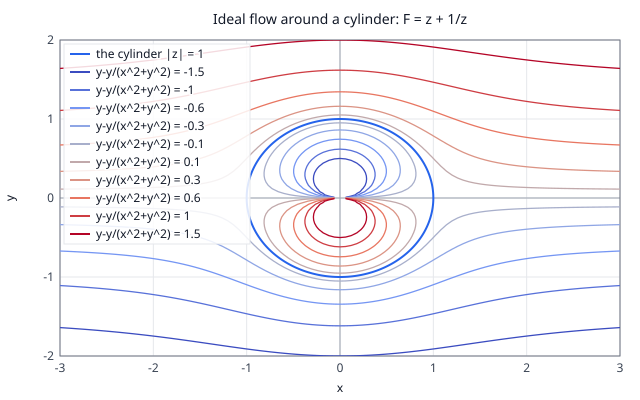

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [5]:
p = parametric(cos(t), sin(t), t, 0, 2*pi);
p = show(p, contour(y - y/(x^2 + y^2), x, -3, 3, y, -2, 2, [-1.5 -1 -0.6 -0.3 -0.1 0.1 0.3 0.6 1 1.5]));
p = window(p, -3, 3, -2, 2);
p = legend(p, "the cylinder |z| = 1");
labels(title(p, "Ideal flow around a cylinder: F = z + 1/z"), "x", "y")

(Inside the circle the curves have no physical meaning.) The velocity $\overline{F'} = \overline{1 - 1/z^2}$ vanishes at
$z = \pm 1$, the **stagnation points** at the front and back of the cylinder, and is largest, $2U$, at the top and
bottom:

In [6]:
solve(1 - 1/z^2, z)
simplify(abs(subs(1 - 1/z^2, z, i)))

[1, -1]

> **Quadratic formula** z = (−b ± sqrt(D))/(2a) with D = b^2 − 4ac = `4`; D > 0: two real roots, rational because D is a perfect square.

2

> `simplify`: simplify(expr) writes expr in one fixed form: a fraction N/D of multiplied-out polynomials (in the symbols, constants and functions of expr) with common factors cancelled, square roots moved out of denominators, and sin^2 + cos^2 = 1 used in whichever direction is shorter.

**Try this.** Check that $\psi = y - y/(x^2 + y^2)$ is harmonic with `laplacian`.

## 4. The Joukowski airfoil

The map $J(z) = z + 1/z$ is conformal except at $z = \pm 1$, where $J' = 1 - 1/z^2 = 0$. It sends the unit circle to the
segment $[-2, 2]$, flattening it twice over. A circle that passes through $z = 1$ but is shifted slightly up and to the
left, so that it encloses $-1$, becomes a **wing profile**: rounded at the front, with a sharp trailing edge where the
circle passes through the critical point 1.

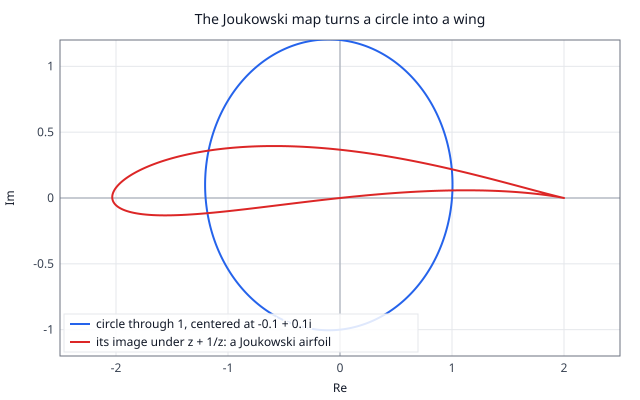

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [7]:
zc = -0.1 + 0.1*i;
rr = abs(1 - zc);
w = zc + rr*exp(i*t);
p = parametric(real(w), imag(w), t, 0, 2*pi);
p = show(p, parametric(real(w + 1/w), imag(w + 1/w), t, 0, 2*pi));
p = window(p, -2.5, 2.5, -1.2, 1.2);
p = legend(p, "circle through 1, centered at -0.1 + 0.1i", "its image under z + 1/z: a Joukowski airfoil");
labels(title(p, "The Joukowski map turns a circle into a wing"), "Re", "Im")

Because $J$ is conformal outside the circle, the flow around the circle, with the uniform stream tilted to the angle of
attack and a circulation $\Gamma$ added, becomes the flow around the wing. Joukowski chose $\Gamma$ so that the flow
leaves the sharp trailing edge smoothly (the **Kutta condition**), and then the **Kutta–Joukowski theorem** gives the
lift per unit span, $\rho U\Gamma$: proportional to air density, speed and circulation. That formula, from a two-line
conformal map, was the start of aerodynamic theory.

**Try this.** Move the center to $-0.1$ (no vertical shift). What shape do you get? What does the vertical shift
control?

## Summary

* An analytic map with $f'(a) \ne 0$ rotates by $\arg f'(a)$ and scales by $|f'(a)|$ near $a$: it preserves angles.
* Möbius maps $(az + b)/(cz + d)$ send circles and lines to circles and lines; $(z - i)/(z + i)$ maps the upper half plane
  onto the unit disc.
* An ideal 2D flow has a complex potential $F = \phi + i\psi$; streamlines are the curves $\psi = \text{const}$, the
  velocity is $\overline{F'}$. $F = U(z + 1/z)$ is the flow past a cylinder.
* The Joukowski map $z + 1/z$ turns circles through 1 into airfoils, and carries the cylinder flow onto them.

This completes the complex analysis path. Its tools come back in physics: Fourier integrals in waves and optics,
residues in quantum scattering, and conformal maps in electrostatics.

## Exercises

1. **Inversion.** Show that $1/z$ maps the circle $|z - 1| = 1$ to the line $\operatorname{Re} w = \tfrac12$. (Hint:
   draw `cmap(1/z, z, 0.5, 2, -1, 1)`, or substitute $z = 1 + e^{it}$ and compute `real(1/(1 + exp(i*t)))`.)
2. **Fixed points.** Find the points with $(z - i)/(z + i) = z$.
3. **Corner flow.** $F = z^2$ describes flow into a corner. Draw its streamlines $\psi = 2xy$ for $x, y > 0$.
4. **Stagnation.** For the flow $F = z + 1/z + i\,\frac{\Gamma}{2\pi}\log z$ with circulation, find where the velocity
   $F' = 1 - 1/z^2 + i\Gamma/(2\pi z)$ vanishes, for $\Gamma = 2\pi$.
5. **Electrostatics.** The potential of a line charge is $\operatorname{Re}\log z = \log|z|$. Use the Cayley map to find
   a harmonic function on the unit disc that is 0 on the circle and has a log singularity at $w = 0$.

## Hints and answers

* **Section 1, Try this.** $(e^z)' = e^z \ne 0$: conformal everywhere. $(z^3 - 3z)' = 3z^2 - 3 = 0$ at $z = \pm 1$.
* **Section 2, Try this.** The real axis goes to the unit circle (minus the point 1), $z = 0$ to $w = -1$, and $z = 5$
  to a point with $|w| = 1$, on the circle.
* **Section 3, Try this.** `simplify(laplacian(y - y/(x^2 + y^2), [x y]))` is 0.
* **Section 4, Try this.** A symmetric airfoil, with no camber. The vertical shift curves the wing (camber).
* **Exercise 1.** `simplify(real(1/(1 + exp(i*t))))` is $\tfrac12$ for every $t$.
* **Exercise 2.** $(z - i)/(z + i) = z$ means $z^2 + (i - 1)z + i = 0$: `solve(z^2 + (i - 1)*z + i, z)`.
* **Exercise 3.** `contour(2*x*y, x, 0, 2, y, 0, 2, [0.2 0.5 1 2 4])`: hyperbolas.
* **Exercise 4.** $z^2 + iz - 1 = 0$ gives $z = (\pm\sqrt3 - i)/2$, two points on the lower half of the circle.
* **Exercise 5.** On the disc it is $\log|w|$: harmonic, 0 on $|w| = 1$, singular at 0. Pulled back by the Cayley map,
  $\log|(z - i)/(z + i)|$ does the same job on the half plane, with the singularity at $z = i$.

## Sources

1. N. Joukowski, "Über die Konturen der Tragflächen der Drachenflieger", *Zeitschrift für Flugtechnik und
   Motorluftschiffahrt* 1 (1910) 281–284.
2. W. M. Kutta, *Illustrierte Aeronautische Mitteilungen* 6 (1902) 133–135.
3. T. Needham, *Visual Complex Analysis*, Oxford University Press (1997), chapters 3, 4 and 12.
4. L. M. Milne-Thomson, *Theoretical Hydrodynamics*, 5th ed., Macmillan (1968), chapters 6 and 7.